# 4.3默认程序按约定修改后的结果

## 环境依赖

In [53]:
import unicodedata
import string
import re
import random
import time
import math

import torch
import torch.nn as nn
from torch import optim
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from nltk.translate.bleu_score import SmoothingFunction,sentence_bleu
from tqdm import tqdm


如果使用GPU，则将下面的变量设为`True`。

In [54]:
USE_CUDA = True

## 读取数据

我们将读取目录下的`cn-eng.txt`文件，其中每一行是一个平行句对，例子如下：

```
我很冷。    I am cold.
```

### 对于单词进行编号

这里引入了两个特殊符号，“SOS”即“Start of sentence”和“EOS”即“End of sentence”。他们会加到输入文本的两端，以控制解码过程。

In [55]:
SOS_token = 0
EOS_token = 1

class Lang:
    def __init__(self, name):
        self.name = name
        self.word2index = {}
        self.word2count = {}
        self.index2word = {0: "SOS", 1: "EOS"}
        self.n_words = 2 # Count SOS and EOS
      
    def index_words(self, sentence):
        if self.name == 'cn':    
            for word in sentence:
                self.index_word(word)
        else:
            for word in sentence.split(' '):
                self.index_word(word)

    def index_word(self, word):
        if word not in self.word2index:
            self.word2index[word] = self.n_words
            self.word2count[word] = 1
            self.index2word[self.n_words] = word
            self.n_words += 1
        else:
            self.word2count[word] += 1

### 文本预处理

丢弃除了中文、字母和常用标点之外的符号。

In [56]:
# Turn a Unicode string to plain ASCII, thanks to http://stackoverflow.com/a/518232/2809427
def unicode_to_ascii(s):
    return ''.join(
        c for c in unicodedata.normalize('NFD', s)
        if unicodedata.category(c) != 'Mn'
    )

# Lowercase, trim, and remove non-letter characters
def normalize_string(s):
    s = unicode_to_ascii(s.lower().strip())
    s = re.sub(r"([.!?])", r" \1", s)
    s = re.sub(r"[^a-zA-Z\u4e00-\u9fa5.!?，。？]+", r" ", s)
    return s

读取平行语料，并进行清理。

In [57]:
def read_langs(lang1, lang2, reverse=False):
    print("Reading lines...")

    # Read the file and split into lines
    lines = open('%s-%s.txt' % (lang1, lang2)).read().strip().split('\n')
    
    # 训练集和验证集按8:2分离     
    lines_train, lines_val = train_test_split(lines, test_size=0.2, random_state=10)

    # Split every line into pairs and normalize
    pairs_train = [[normalize_string(s) for s in l.split('\t')] for l in lines_train]
    pairs_val = [[normalize_string(s) for s in l.split('\t')] for l in lines_val]
    
    # Reverse pairs, make Lang instances
    if reverse:
        pairs = [list(reversed(p)) for p in pairs]
        input_lang = Lang(lang2)
        output_lang = Lang(lang1)
    else:
        input_lang = Lang(lang1)
        output_lang = Lang(lang2)
        
    return input_lang, output_lang, pairs_train, pairs_val

### 过滤句子

样例为了加快训练，只保留了不长于10个单词的句对，真正实验中将更多数据考虑进来可能获得更好的效果。

In [58]:
MAX_LENGTH = 40

def filter_pair(p):
    return len(p[1].split(' ')) < MAX_LENGTH

def filter_pairs(pairs):
    return [pair for pair in pairs if filter_pair(pair)]

处理数据的全过程：

- 读取数据，每一行分别处理，将其转换成句对
- 对于文本进行处理，过滤无用符号
- 根据已有文本对于单词进行编号，构建符号到编号的映射


In [59]:
def prepare_data(lang1_name, lang2_name, reverse=False):
        
    input_lang, output_lang, pairs_train, pairs_val = read_langs(lang1_name, lang2_name, reverse)
    print("Read %s sentence pairs for train" % len(pairs_train))
    pairs_train = filter_pairs(pairs_train)
    print("Trimmed to %s sentence pairs for train" % len(pairs_train))
    print("Read %s sentence pairs for validate" % len(pairs_val))
    pairs_val = filter_pairs(pairs_val)
    print("Trimmed to %s sentence pairs for validate" % len(pairs_val))

    print("Indexing words...")
    for pair in pairs_train:
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])
    for pair in pairs_val:
        input_lang.index_words(pair[0])
        output_lang.index_words(pair[1])

    return input_lang, output_lang, pairs_train, pairs_val

# 训练集:pairs_train; 验证集:pairs_val
input_lang, output_lang, pairs_train, pairs_val = prepare_data('cn', 'eng', False)

# 随机打印一条训练集和验证集的句对
print(random.choice(pairs_train))
print(random.choice(pairs_val))

Reading lines...
Read 72000 sentence pairs for train
Trimmed to 71903 sentence pairs for train
Read 18000 sentence pairs for validate
Trimmed to 17978 sentence pairs for validate
Indexing words...
['中国给我许多不同的印象。', 'china gives me many different impressions .']
['她給了我一本的書作為聖誕禮物。', 'she gave me a book for christmas .']


## 将文本数据转换为张量

为了训练，我们需要将句子变成神经网络可以理解的东西（数字）。每个句子将被分解成单词，然后变成张量，其中每个单词都被索引替换（来自之前的Lang索引）。在创建这些张量时，我们还将附加EOS令牌以表示该句子已结束。

![](https://i.imgur.com/LzocpGH.png)

In [60]:
# Return a list of indexes, one for each word in the sentence
def indexes_from_sentence(lang, sentence):
    if lang.name == 'cn':
        return [lang.word2index[word] for word in sentence]
    else:
        return [lang.word2index[word] for word in sentence.split(' ')]

def variable_from_sentence(lang, sentence):
    indexes = indexes_from_sentence(lang, sentence)
    indexes.append(EOS_token)
    var = torch.LongTensor(indexes).view(-1, 1)
    if USE_CUDA: var = var.cuda()
    return var

def variables_from_pair(pair):
    input_variable = variable_from_sentence(input_lang, pair[0])
    target_variable = variable_from_sentence(output_lang, pair[1])
    return (input_variable, target_variable)

# 组件模型

## 编码器

In [61]:
class EncoderRNN(nn.Module):
    def __init__(self, input_size, hidden_size, n_layers=1):
        super(EncoderRNN, self).__init__()
        
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        
        self.embedding = nn.Embedding(input_size, hidden_size)
        self.rnn = nn.RNN(hidden_size, hidden_size, n_layers)
        
    def forward(self, word_inputs, hidden):
        # Note: we run this all at once (over the whole input sequence)
        seq_len = len(word_inputs)
        embedded = self.embedding(word_inputs).view(seq_len, 1, -1)
        output, hidden = self.rnn(embedded, hidden)
        return output, hidden

    def init_hidden(self):
        hidden = torch.zeros(self.n_layers, 1, self.hidden_size)
        if USE_CUDA: 
            hidden = hidden.cuda()
        return hidden

## 解码器

In [62]:
class DecoderRNN(nn.Module):
    def __init__(self, hidden_size, output_size, n_layers=1, dropout_p=0.1):
        super(DecoderRNN, self).__init__()
        
        # Keep parameters for reference
        self.hidden_size = hidden_size
        self.output_size = output_size
        self.n_layers = n_layers
        self.dropout_p = dropout_p
        
        # Define layers
        self.embedding = nn.Embedding(output_size, hidden_size)
        self.rnn = nn.RNN(hidden_size, hidden_size, n_layers, dropout=dropout_p)
        self.out = nn.Linear(hidden_size, output_size)
    
    def forward(self, word_input, last_hidden):
        # Note: we run this one step at a time        
        word_embedded = self.embedding(word_input).view(1, 1, -1) # S=1 x B x N
        rnn_output, hidden = self.rnn(word_embedded, last_hidden)

        rnn_output = rnn_output.squeeze(0)
        output = F.log_softmax(self.out(rnn_output), dim=1)

        return output, hidden

# 训练

## 一次训练迭代

为了训练，我们首先通过编码器逐字运行输入语句，并跟踪每个输出和最新的隐藏状态。接下来，为解码器提供解码器的最后一个隐藏状态作为其第一隐藏状态，并向其提供`<SOS>`作为其第一输入。从那里开始，我们迭代地预测来自解码器的下一个单词。
    
### Teacher Forcing 和 Scheduled Sampling

"Teacher Forcing"指的是每次都基于完全准确的上文进行解码，这样训练模型收敛很快，但是会造成实际场景和训练场景有较大差别，因为实际场景上文也都是模型预测的，可能不准确，具体细节可参考[论文](http://minds.jacobs-university.de/sites/default/files/uploads/papers/ESNTutorialRev.pdf)。

观察Teacher Forcing的网络的输出，我们可以看到该网络语法连贯，但是偏离正确的翻译。可以将其为学会了如何听老师的指示，而未学习如何独自冒险。

解决强迫教师问题的方法称为“计划抽样”（[Scheduled Sampling](https://arxiv.org/abs/1506.03099)），它在训练时仅在使用目标值和预测值之间进行切换。我们将在训练时随机选择,有时我们将使用真实目标作为输入（忽略解码器的输出），有时我们将使用解码器的输出。

In [63]:
teacher_forcing_ratio = 0.5
clip = 5.0

def train(input_variable, target_variable, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion, max_length=MAX_LENGTH):

    # Zero gradients of both optimizers
    encoder_optimizer.zero_grad()
    decoder_optimizer.zero_grad()
    loss = 0 # Added onto for each word

    # Get size of input and target sentences
    input_length = input_variable.size()[0]
    target_length = target_variable.size()[0]

    # Run words through encoder
    encoder_hidden = encoder.init_hidden()
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)
    
    # Prepare input and output variables
    decoder_input = torch.LongTensor([[SOS_token]])
    decoder_hidden = encoder_hidden # Use last hidden state from encoder to start decoder
    if USE_CUDA:
        decoder_input = decoder_input.cuda()

    # Choose whether to use teacher forcing
    use_teacher_forcing = random.random() < teacher_forcing_ratio
    if use_teacher_forcing:        
        # Teacher forcing: Use the ground-truth target as the next input
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
            loss += criterion(decoder_output, target_variable[di])
            decoder_input = target_variable[di] # Next target is next input

    else:
        # Without teacher forcing: use network's own prediction as the next input
        for di in range(target_length):
            decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
            loss += criterion(decoder_output, target_variable[di])
            
            # Get most likely word index (highest value) from output
            topv, topi = decoder_output.data.topk(1)
            ni = topi[0][0]
            
            decoder_input = torch.LongTensor([[ni]]) # Chosen word is next input
            if USE_CUDA: 
                decoder_input = decoder_input.cuda()

            # Stop at end of sentence (not necessary when using known targets)
            if ni == EOS_token: 
                break

    # Backpropagation
    loss.backward()
    torch.nn.utils.clip_grad_norm_(encoder.parameters(), clip)
    torch.nn.utils.clip_grad_norm_(decoder.parameters(), clip)
    encoder_optimizer.step()
    decoder_optimizer.step()
    
    return loss.item() / target_length

下面是用于辅助输出训练情况的函数

In [64]:
def as_minutes(s):
    m = math.floor(s / 60)
    s -= m * 60
    return '%dm %ds' % (m, s)

def time_since(since, percent):
    now = time.time()
    s = now - since
    es = s / (percent)
    rs = es - s
    return '%s (- %s)' % (as_minutes(s), as_minutes(rs))

## 进行训练

In [65]:
hidden_size = 500
n_layers = 2
dropout_p = 0.05

# Initialize models
encoder = EncoderRNN(input_lang.n_words, hidden_size, n_layers)
decoder = DecoderRNN(hidden_size, output_lang.n_words, n_layers, dropout_p=dropout_p)

# Move models to GPU
if USE_CUDA:
    encoder.cuda()
    decoder.cuda()

# Initialize optimizers and criterion
learning_rate = 0.0001
encoder_optimizer = optim.Adam(encoder.parameters(), lr=learning_rate)
decoder_optimizer = optim.Adam(decoder.parameters(), lr=learning_rate)
criterion = nn.NLLLoss()

以下设置变量用于绘制图标和跟踪进度：

In [66]:
# Configuring training
n_epochs = 143808
plot_every = 1000  
print_every = 2000

# Keep track of time elapsed and running averages
start = time.time()
plot_losses = []
print_loss_total = 0 # Reset every print_every
plot_loss_total = 0 # Reset every plot_every

要进行实际训练，我们会多次调用训练函数，并在进行过程中打印中间信息。

In [67]:
# Begin!
for epoch in range(1, n_epochs + 1):
    
    # Get training data for this cycle
    training_pair = variables_from_pair(random.choice(pairs_train))
    input_variable = training_pair[0]
    target_variable = training_pair[1]

    # Run the train function
    loss = train(input_variable, target_variable, encoder, decoder, encoder_optimizer, decoder_optimizer, criterion)

    # Keep track of loss
    print_loss_total += loss
    plot_loss_total += loss

    if epoch == 0: continue

    if epoch % print_every == 0:
        print_loss_avg = print_loss_total / print_every
        print_loss_total = 0
        print_summary = '%s (%d %d%%) %.4f' % (time_since(start, epoch / n_epochs), epoch, epoch / n_epochs * 100, print_loss_avg)
        print(print_summary)

    if epoch % plot_every == 0:
        plot_loss_avg = plot_loss_total / plot_every
        plot_losses.append(plot_loss_avg)
        plot_loss_total = 0

0m 26s (- 30m 57s) (2000 1%) 4.9812
0m 53s (- 30m 53s) (4000 2%) 4.6510
1m 19s (- 30m 31s) (6000 4%) 4.5073
1m 46s (- 30m 6s) (8000 5%) 4.4098
2m 12s (- 29m 39s) (10000 6%) 4.3216
2m 39s (- 29m 14s) (12000 8%) 4.3150
3m 6s (- 28m 46s) (14000 9%) 4.2548
3m 32s (- 28m 17s) (16000 11%) 4.2415
3m 59s (- 27m 50s) (18000 12%) 4.2378
4m 25s (- 27m 26s) (20000 13%) 4.2051
4m 52s (- 27m 2s) (22000 15%) 4.1812
5m 19s (- 26m 36s) (24000 16%) 4.1652
5m 47s (- 26m 12s) (26000 18%) 4.2156
6m 13s (- 25m 45s) (28000 19%) 4.2113
6m 40s (- 25m 19s) (30000 20%) 4.1444
7m 7s (- 24m 53s) (32000 22%) 4.1256
7m 34s (- 24m 27s) (34000 23%) 4.1227
8m 1s (- 24m 2s) (36000 25%) 4.1634
8m 29s (- 23m 37s) (38000 26%) 4.1661
8m 56s (- 23m 12s) (40000 27%) 4.1576
9m 24s (- 22m 47s) (42000 29%) 4.1901
9m 51s (- 22m 21s) (44000 30%) 4.1468
10m 19s (- 21m 56s) (46000 31%) 4.1469
10m 46s (- 21m 30s) (48000 33%) 4.1222
11m 13s (- 21m 3s) (50000 34%) 4.1139
11m 40s (- 20m 37s) (52000 36%) 4.0603
12m 8s (- 20m 11s) (54000 

## 绘制训练loss

In [68]:
plot_losses

[5.2108189733923345,
 4.751558917870718,
 4.741723998466533,
 4.560297954921096,
 4.572323449601433,
 4.442265607121459,
 4.50567175087979,
 4.3139901061358055,
 4.242179591359141,
 4.40093848290376,
 4.343144326800276,
 4.286846992375796,
 4.204128566103219,
 4.305405678841559,
 4.185876277413696,
 4.2970487403275035,
 4.262640772090311,
 4.212923017904038,
 4.203811503177257,
 4.206361855021762,
 4.151257629237417,
 4.211168245269587,
 4.138356469034657,
 4.192056849912974,
 4.204503557488862,
 4.226784355800737,
 4.230451713540489,
 4.192074530985731,
 4.090010855284115,
 4.19874406209912,
 4.146766024695117,
 4.104383259547507,
 4.133427966935447,
 4.11206139854396,
 4.213462368650768,
 4.113387823208077,
 4.2083143084134935,
 4.123888282683829,
 4.141160061790493,
 4.174031719384374,
 4.180307918109121,
 4.199897465638314,
 4.178174406103114,
 4.115451962053144,
 4.168062754867005,
 4.125795694497664,
 4.127193889410314,
 4.1172602244522425,
 4.145072731438198,
 4.082668779767212,

<Figure size 640x480 with 0 Axes>

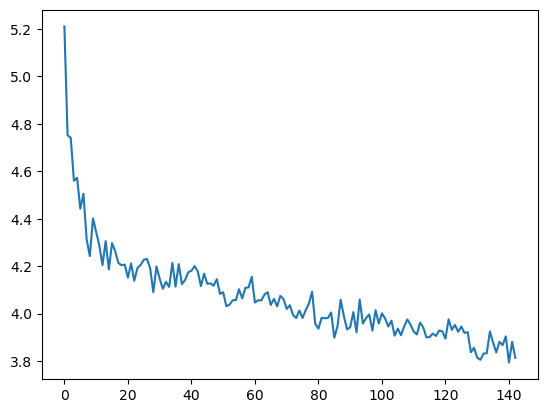

In [69]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
%matplotlib inline

def show_plot(points):
    plt.figure()
    fig, ax = plt.subplots()
    loc = ticker.MultipleLocator(base=0.2) # put ticks at regular intervals
    ax.yaxis.set_major_locator(loc)
    plt.plot(points)

show_plot(plot_losses)

# 模型验证

In [70]:
def evaluate(sentence, max_length=MAX_LENGTH):
    input_variable = variable_from_sentence(input_lang, sentence)
    input_length = input_variable.size()[0]
    
    # Run through encoder
    encoder_hidden = encoder.init_hidden()
    encoder_outputs, encoder_hidden = encoder(input_variable, encoder_hidden)

    # Create starting vectors for decoder
    decoder_input = torch.LongTensor([[SOS_token]]) # SOS
    if USE_CUDA:
        decoder_input = decoder_input.cuda()

    decoder_hidden = encoder_hidden
    
    decoded_words = []
    decoder_attentions = torch.zeros(max_length, max_length)
    
    # Run through decoder
    for di in range(max_length):
        decoder_output, decoder_hidden = decoder(decoder_input, decoder_hidden)
        # Choose top word from output
        topv, topi = decoder_output.data.topk(1)
        ni = topi[0][0]
        if ni == EOS_token:
            decoded_words.append('<EOS>')
            break
        else:
            decoded_words.append(output_lang.index2word[ni.item()])
            
        # Next input is chosen word
        # decoder_input = torch.LongTensor([[ni]])
        decoder_input = topi.squeeze().detach()
        if USE_CUDA: 
            decoder_input = decoder_input.cuda()
    
    return decoded_words

### 取约定的数据进行验证

In [71]:
val_man = ['美國在一八六三年廢除了奴隸制度。',
            '关门。',
            '我不喝水。',
            '请安装 linux !',
            '为什么我还在这里？',
            '這本書有一個弱點 作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。']

pairs_man= []
for pair in pairs_val:
    if pair[0] in val_man and pair not in pairs_man:          
        pairs_man.append(pair) 
        output_words = evaluate(pair[0])
        output_sentence = ' '.join(output_words)
        
        print('>', pair[0])
        print('=', pair[1])
        print('<', output_sentence)
        print('')

> 我不喝水。
= i don t drink water .
< i m not too . <EOS>

> 为什么我还在这里？
= why am i still here ?
< why do you want to go to ? <EOS>

> 请安装 linux !
= install linux !
< please take a the . <EOS>

> 美國在一八六三年廢除了奴隸制度。
= america did away with slavery in .
< the is is to is in . the . <EOS>

> 关门。
= close the door .
< keep him . <EOS>

> 這本書有一個弱點 作者自己結了婚，但卻建議別人不要結婚，沒有甚麼說服力。
= the weak point of this book is that it s less than persuasive when the married author recommends not being married .
< this is is not to is to . . . <EOS>



### 验证集上的BLEU

In [72]:
bleu_scores = list() 

with torch.no_grad():    
    for pair in tqdm(pairs_val):
        output_words = evaluate(pair[0])
        output_words.pop(len(output_words)-1)
        bleu_score = sentence_bleu([pair[1].split()], output_words, smoothing_function= SmoothingFunction().method4)
        bleu_scores.append(bleu_score)
bleu_scores_avg =  np.average(bleu_scores)
bleu_scores_avg

100%|██████████| 17978/17978 [00:52<00:00, 343.16it/s]


0.0547025051291569

### 保存模型

In [73]:
state = {'epoch': n_epochs,
    'bleu': bleu_scores_avg,
    'encoder': encoder,
    'decoder': decoder,
    'encoder_optimizer': encoder_optimizer,
    'decoder_optimizer': decoder_optimizer}
filename = './output/4.3.default.pth.tar'
torch.save(state, filename)